# Does vulnerable employment increase during a recession?

**ECON 630 project.** This notebook follows the plan in [`Claude.MD`](Claude.MD). All data are pulled from the World Bank API inside the notebook, so anyone can re-run it top to bottom.

**Hypothesis:** Vulnerable employment increases during a recession because formal employment opportunities dry up, pushing workers into own-account work and contributing family work.

**Plan of the notebook**

1. Setup
2. Pull the data from the World Bank API (`wbgapi`)
3. Cross-check the API pull against the CSVs saved in the ECON630 folder
4. Clean: drop regional/income aggregates, reshape to a country–year panel
5. Define recessions and the outcome variable
6. Descriptive comparison: recession vs. non-recession years
7. Panel regression with country and year fixed effects
8. Event study around recession onsets
9. Heterogeneity by income group
10. Conclusions and caveats

## 1. Setup

In [1]:
from pathlib import Path
import re
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
import wbgapi as wb

START, END = 1991, 2025          # ILO modeled estimates start in 1991

# Optional saved World Bank CSVs (repo root or this folder), used only for the cross-check in step 3
DATA_DIR = next((p for p in [Path.cwd(), Path.cwd().parent]
                 if any(p.glob("API_SL.EMP.VULN.ZS*.zip"))), None)

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
SOURCE = "Source: World Bank WDI via wbgapi (SL.EMP.VULN.ZS, modeled ILO estimate; NY.GDP.MKTP.KD.ZG)."

BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": "#333", "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "axes.axisbelow": True,
})
pd.set_option("display.float_format", "{:.3f}".format)

def finish(fig, name):
    # add the data-source caption, save to figures/, and display

    fig.text(0.01, -0.03, SOURCE, fontsize=8, color=MUTED, ha="left", va="top")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

### API keys

The World Bank API is free and doesn't need a key, so this project has no secrets. If a key-protected source is added later, put the key in a `.env` file (already excluded by `.gitignore`) and read it with `os.getenv`. Keys never go in the notebook or the repo.

In [2]:
import os
from dotenv import load_dotenv

load_dotenv()   # loads variables from a local .env file if one exists; does nothing otherwise
# e.g. FRED_KEY = os.getenv("FRED_API_KEY")   # not needed for the World Bank API

False

## 2. Pull the data from the World Bank API

| Code | Indicator | Role |
|---|---|---|
| `SL.EMP.VULN.ZS` | Vulnerable employment, % of total employment (modeled ILO estimate) | **Outcome** |
| `NY.GDP.MKTP.KD.ZG` | GDP growth, annual %, constant prices | **Recession indicator** |
| `NY.GDP.MKTP.CD` | GDP, current US$ | Matches the saved CSV; used only for the cross-check |

The recession indicator is **real** GDP growth. Current-US$ GDP moves with exchange rates and inflation, so a fall in nominal dollar GDP doesn't mean the economy contracted.

In [3]:
SERIES = {
    "SL.EMP.VULN.ZS":    "vuln",
    "NY.GDP.MKTP.KD.ZG": "gdp_growth",
    "NY.GDP.MKTP.CD":    "gdp_usd",
}

economies = wb.economy.DataFrame()
raw = wb.data.DataFrame(list(SERIES), economy="all", time=range(START, END + 1),
                        columns="series").reset_index()
raw.head()

,economy,time,NY.GDP.MKTP.CD,NY.GDP.MKTP.KD.ZG,SL.EMP.VULN.ZS
0,ABW,YR1991,872067039.106,7.963,NaN
1,ABW,YR1992,958659217.877,5.882,NaN
2,ABW,YR1993,1083240223.464,7.308,NaN
3,ABW,YR1994,1245810055.866,8.204,NaN
4,ABW,YR1995,1320670391.061,2.547,NaN


## 3. Cross-check against the CSVs in the ECON630 folder

The zipped World Bank CSVs are wide (one column per year) and have four lines of header metadata. If they agree with the API pull, we know we're using the same data. This step is **optional**: the analysis uses only the API data, and the step is skipped if the zip files aren't present.

In [4]:
def load_wb_zip(path, name):
    with zipfile.ZipFile(path) as z:
        csv = next(f for f in z.namelist() if f.startswith("API_"))
        wide = pd.read_csv(z.open(csv), skiprows=4)
    year_cols = [c for c in wide.columns if c.isdigit()]
    return (wide.melt(id_vars="Country Code", value_vars=year_cols, var_name="year", value_name=name)
                .rename(columns={"Country Code": "iso3"})
                .astype({"year": int}))

if DATA_DIR is None:
    print("Saved CSV zips not found; skipping the cross-check (the analysis uses only the API pull).")
else:
    local = load_wb_zip(next(DATA_DIR.glob("API_SL.EMP.VULN.ZS*.zip")), "vuln_local").merge(
            load_wb_zip(next(DATA_DIR.glob("API_NY.GDP.MKTP.CD*.zip")), "gdp_usd_local"),
            on=["iso3", "year"], how="outer")

    api_check = raw.assign(year=raw["time"].str[2:].astype(int)).rename(columns={"economy": "iso3"})
    chk = api_check.merge(local, on=["iso3", "year"], how="inner")

    for api_col, loc_col in [("SL.EMP.VULN.ZS", "vuln_local"), ("NY.GDP.MKTP.CD", "gdp_usd_local")]:
        both = chk[[api_col, loc_col]].dropna()
        rel = ((both[api_col] - both[loc_col]).abs() / both[loc_col].abs()).max()
        print(f"{api_col:16s} overlapping obs = {len(both):5d}   max relative difference = {rel:.2e}")

SL.EMP.VULN.ZS   overlapping obs =  8176   max relative difference = 0.00e+00
NY.GDP.MKTP.CD   overlapping obs =  8854   max relative difference = 0.00e+00


## 4. Clean the data

* Convert `YR2009` → `2009`.
* **Drop aggregates.** The World Bank bundles regions and income groups ("World", "Euro area", "Low income", …) in with countries. Leaving them in would double-count countries.
* Attach country name and income group.
* Keep countries with at least 10 years of both variables.

In [5]:
countries = economies.loc[~economies["aggregate"], ["name", "incomeLevel", "region"]]

panel = (raw.rename(columns=SERIES | {"economy": "iso3"})
            .assign(year=lambda d: d["time"].str[2:].astype(int))
            .drop(columns="time")
            .merge(countries, left_on="iso3", right_index=True, how="inner")
            .sort_values(["iso3", "year"])
            .reset_index(drop=True))

print(f"Rows before filtering: {len(panel):,}   countries: {panel['iso3'].nunique()}")

n_obs = panel.dropna(subset=["vuln", "gdp_growth"]).groupby("iso3").size()
panel = panel[panel["iso3"].isin(n_obs[n_obs >= 10].index)].copy()

print(f"Rows after filtering:  {len(panel):,}   countries: {panel['iso3'].nunique()}")
print(f"Years covered: {panel.dropna(subset=['vuln'])['year'].min()}–{panel.dropna(subset=['vuln'])['year'].max()}")
panel[["vuln", "gdp_growth"]].describe().T

Rows before filtering: 7,595   countries: 217
Rows after filtering:  6,475   countries: 185
Years covered: 1991–2025


,count,mean,std,min,25%,50%,75%,max
vuln,6463.000,37.459,26.497,0.200,13.743,32.275,58.862,95.530
gdp_growth,6325.000,3.408,6.765,-64.047,1.343,3.642,5.909,149.973


## 5. Define recessions and the outcome

* **Recession year:** real GDP growth < 0. With annual data this is the standard cross-country definition; the NBER-style quarterly definition isn't available for most countries.
* **Recession onset:** a recession year that follows a non-recession year.
* **Outcome:** the year-over-year change in vulnerable employment, in percentage points: $\Delta vuln_{it} = vuln_{it} - vuln_{i,t-1}$. The hypothesis is about vulnerable employment *increasing*, and differencing also strips out each country's permanent level (for example, Niger ≈ 90% vs. Germany ≈ 6%).

In [6]:
g = panel.groupby("iso3")
panel["recession"]     = (panel["gdp_growth"] < 0).astype(float).where(panel["gdp_growth"].notna())
panel["recession_lag"] = g["recession"].shift(1)
panel["onset"]         = ((panel["recession"] == 1) & (panel["recession_lag"] == 0)).astype(int)
panel["d_vuln"]        = g["vuln"].diff()
panel["d_vuln_lead"]   = g["d_vuln"].shift(-1)   # change in the year after

reg = panel.dropna(subset=["d_vuln", "recession"])
print(f"Country-years with outcome + recession flag: {len(reg):,}")
print(f"Recession country-years: {int(reg['recession'].sum()):,} ({reg['recession'].mean():.1%})")
print(f"Recession onsets:        {int(reg['onset'].sum()):,}")

Country-years with outcome + recession flag: 6,138
Recession country-years: 950 (15.5%)
Recession onsets:        573


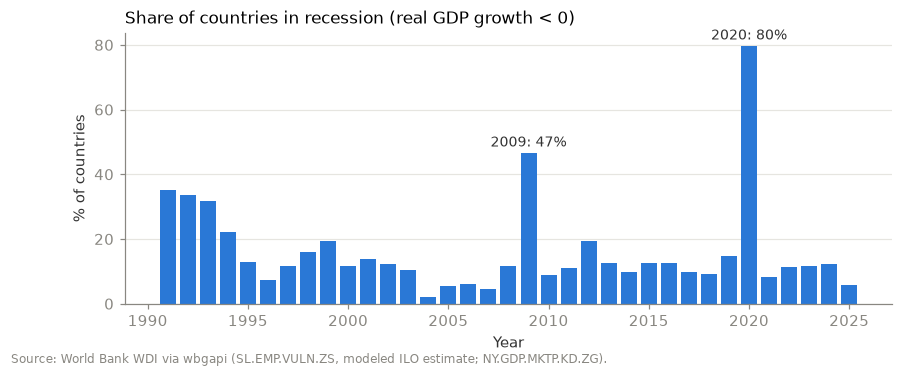

In [7]:
share = panel.dropna(subset=["recession"]).groupby("year")["recession"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(share.index, share.values, color=BLUE, width=0.8)
for yr in [2009, 2020]:
    ax.annotate(f"{yr}: {share[yr]:.0f}%", (yr, share[yr]), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=9, color="#333")
ax.set_title("Share of countries in recession (real GDP growth < 0)", loc="left", fontsize=11)
ax.set_ylabel("% of countries"); ax.set_xlabel("Year"); ax.grid(axis="x", visible=False)
finish(fig, "1_share_in_recession")

## 6. Descriptive comparison

Is vulnerable employment's average annual change larger in recession years? A Welch t-test compares the two groups without assuming equal variances. This is only a first look: country-years aren't independent, which the next step deals with.

In [8]:
summary = (reg.groupby("recession")["d_vuln"]
              .agg(["count", "mean", "median", "std"])
              .rename(index={0.0: "No recession", 1.0: "Recession"}))
display(summary)

rec, norec = reg.loc[reg["recession"] == 1, "d_vuln"], reg.loc[reg["recession"] == 0, "d_vuln"]
t, p = stats.ttest_ind(rec, norec, equal_var=False)
print(f"Difference in means (recession − no recession): {rec.mean() - norec.mean():+.3f} pp   t = {t:.2f}, p = {p:.4f}")

,count,mean,median,std
recession,,,,
No recession,5188,-0.234,-0.187,0.778
Recession,950,0.184,0.077,0.694


Difference in means (recession − no recession): +0.418 pp   t = 16.73, p = 0.0000


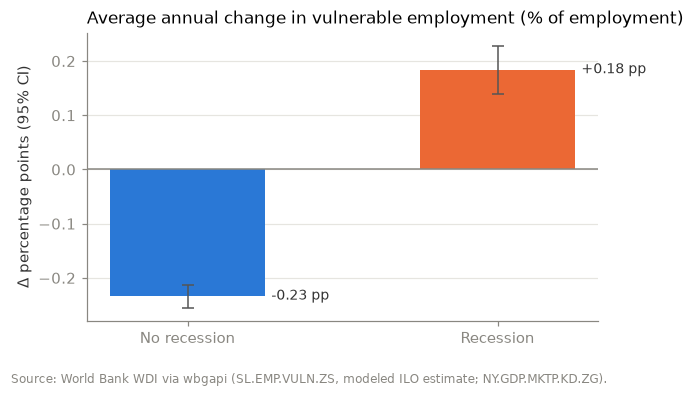

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.4))
means = summary["mean"]
se = summary["std"] / np.sqrt(summary["count"])
ax.bar(means.index, means.values, yerr=1.96 * se.values, color=[BLUE, ORANGE], width=0.5,
       capsize=4, error_kw={"ecolor": "#555", "elinewidth": 1})
ax.axhline(0, color=MUTED, linewidth=1)
for i, v in enumerate(means.values):
    ax.annotate(f"{v:+.2f} pp", (i + 0.27, v), ha="left", va="center", fontsize=9, color="#333")
ax.set_title("Average annual change in vulnerable employment (% of employment)", loc="left", fontsize=11)
ax.set_ylabel("Δ percentage points (95% CI)"); ax.grid(axis="x", visible=False)
finish(fig, "2_mean_change_by_recession")

## 7. Panel regression with fixed effects

$$\Delta vuln_{it} = \beta_1\,Recession_{it} + \beta_2\,Recession_{i,t-1} + \alpha_i + \gamma_t + \varepsilon_{it}$$

* $\alpha_i$ (**country fixed effects**) absorb each country's own trend in vulnerable employment. Most developing countries have been formalizing steadily for decades.
* $\gamma_t$ (**year fixed effects**) absorb global shocks and anything that changes ILO modelling from year to year.
* The **lagged recession** term allows for labour markets responding with a delay.
* Standard errors are **clustered by country**, since one country's errors are correlated over time.

$\beta_1 > 0$ would support the hypothesis.

In [10]:
def fe_ols(formula, data):
    # keep only rows complete on the variables in the formula, so cluster groups line up
    used = set(re.findall(r"[A-Za-z_]\w*", formula)) & set(data.columns)
    d = data.dropna(subset=list(used)).copy()
    return smf.ols(formula, data=d).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d["iso3"])[0]})

specs = {
    "(1) Recession, no FE":         "d_vuln ~ recession",
    "(2) + country & year FE":      "d_vuln ~ recession + C(iso3) + C(year)",
    "(3) + lagged recession":       "d_vuln ~ recession + recession_lag + C(iso3) + C(year)",
    "(4) Continuous GDP growth":    "d_vuln ~ gdp_growth + C(iso3) + C(year)",
}
cols = ["recession", "recession_lag", "gdp_growth"]
models = {name: fe_ols(f, panel) for name, f in specs.items()}

rows = {}
for name, m in models.items():
    r = {}
    for c in cols:
        if c in m.params:
            stars = "***" if m.pvalues[c] < .01 else "**" if m.pvalues[c] < .05 else "*" if m.pvalues[c] < .1 else ""
            r[c] = f"{m.params[c]:.3f}{stars}\n({m.bse[c]:.3f})"
    r["N"] = f"{int(m.nobs):,}"
    r["Countries"] = str(len(set(m.model.data.frame["iso3"])))
    rows[name] = r
results_table = pd.DataFrame(rows).reindex(cols + ["N", "Countries"]).fillna("")
print("Dependent variable: annual change in vulnerable employment (pp). Clustered SEs in parentheses.")
print("* p<0.10, ** p<0.05, *** p<0.01")
display(results_table.style.set_properties(**{"white-space": "pre-wrap", "text-align": "center"}))

Dependent variable: annual change in vulnerable employment (pp). Clustered SEs in parentheses.
* p<0.10, ** p<0.05, *** p<0.01


,"(1) Recession, no FE",(2) + country & year FE,(3) + lagged recession,(4) Continuous GDP growth
recession,0.418*** (0.034),0.326*** (0.041),0.279*** (0.039),
recession_lag,,,0.200*** (0.033),
gdp_growth,,,,-0.021*** (0.003)
N,"6,138","6,138","6,128","6,138"
Countries,185,185,185,185


**How to read the table:** the `recession` coefficient is the extra percentage-point change in vulnerable employment in a recession year, relative to the same country in a normal year after netting out global year effects. In column (4), the `gdp_growth` coefficient is the change associated with 1 point faster growth. A **negative** sign there means vulnerable employment rises as growth falls, which is consistent with the hypothesis.

## 8. Event study around recession onsets

The regression gives an average effect. An event study shows its *timing*: does vulnerable employment start rising before the recession (a warning sign for reverse causality), jump when it hits, and does the rise persist?

For every recession onset we take the vulnerable-employment level from 3 years before to 4 years after. Each event is normalised to its level in the year **before** onset ($t=-1$), and we average across events. A plain average would mostly show the secular downward trend in vulnerable employment. To remove it, the same calculation is also run on placebo "events", which are all non-recession country-years with no recession in their window, and subtracted.

In [11]:
WINDOW = range(-3, 5)
vuln_wide = panel.pivot(index="iso3", columns="year", values="vuln")
rec_wide  = panel.pivot(index="iso3", columns="year", values="recession")

def event_paths(pairs):
    out = []
    for iso, yr in pairs:
        yrs = [yr + k for k in WINDOW]
        if all(y in vuln_wide.columns for y in yrs):
            path = vuln_wide.loc[iso, yrs].to_numpy(dtype=float)
            base = vuln_wide.loc[iso, yr - 1]
            if not np.isnan(path).any():
                out.append(path - base)
    return np.array(out)

events = event_paths(panel.loc[panel["onset"] == 1, ["iso3", "year"]].itertuples(index=False))

# Placebo: country-years with no recession anywhere in the window
calm = []
for iso, yr in panel[["iso3", "year"]].itertuples(index=False):
    yrs = [yr + k for k in WINDOW]
    if all(y in rec_wide.columns for y in yrs) and (rec_wide.loc[iso, yrs] == 0).all():
        calm.append((iso, yr))
placebo = event_paths(calm)

diff = events.mean(0) - placebo.mean(0)
se = np.sqrt(events.var(0, ddof=1) / len(events) + placebo.var(0, ddof=1) / len(placebo))
es = pd.DataFrame({"event_time": list(WINDOW), "recession_path": events.mean(0),
                   "placebo_path": placebo.mean(0), "difference": diff,
                   "ci_low": diff - 1.96 * se, "ci_high": diff + 1.96 * se})
print(f"Recession onsets with a full window: {len(events)}   placebo windows: {len(placebo)}")
es.set_index("event_time")

Recession onsets with a full window: 491   placebo windows: 2000


,recession_path,placebo_path,difference,ci_low,ci_high
event_time,,,,,
-3,0.316,0.549,-0.232,-0.342,-0.122
-2,0.135,0.283,-0.148,-0.224,-0.072
-1,0.000,0.000,0.000,0.000,0.000
0,0.129,-0.277,0.406,0.335,0.476
1,0.043,-0.562,0.605,0.483,0.727
2,-0.033,-0.842,0.809,0.658,0.960
3,-0.198,-1.122,0.923,0.735,1.112
4,-0.295,-1.390,1.095,0.883,1.308


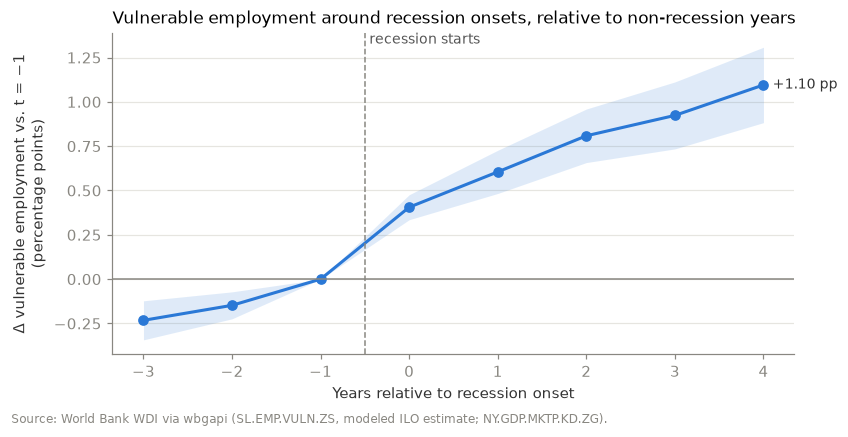

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.fill_between(es["event_time"], es["ci_low"], es["ci_high"], color=BLUE, alpha=0.15, linewidth=0)
ax.plot(es["event_time"], es["difference"], color=BLUE, marker="o", markersize=6)
ax.axhline(0, color=MUTED, linewidth=1)
ax.axvline(-0.5, color=MUTED, linewidth=1, linestyle="--")
ax.annotate("recession starts", (-0.45, ax.get_ylim()[1]), va="top", fontsize=9, color="#555")
last = es.iloc[-1]
ax.annotate(f"{last['difference']:+.2f} pp", (last["event_time"], last["difference"]),
            xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="#333")
ax.set_xticks(list(WINDOW))
ax.set_xlabel("Years relative to recession onset")
ax.set_ylabel("Δ vulnerable employment vs. t = −1\n(percentage points)")
ax.set_title("Vulnerable employment around recession onsets, relative to non-recession years",
             loc="left", fontsize=11)
ax.grid(axis="x", visible=False)
finish(fig, "3_event_study")

## 9. Heterogeneity by income group

The mechanism in the hypothesis, where workers fall back on informal self-employment when formal jobs disappear, should be strongest where informality is common and unemployment insurance is thin. We rerun spec (3) separately for each World Bank income group.

In [13]:
INCOME = {"LIC": "Low income", "LMC": "Lower-middle", "UMC": "Upper-middle", "HIC": "High income"}
het = []
for code_, label in INCOME.items():
    m = fe_ols("d_vuln ~ recession + recession_lag + C(iso3) + C(year)",
               panel[panel["incomeLevel"] == code_])
    het.append({"group": label, "beta": m.params["recession"], "se": m.bse["recession"],
                "p": m.pvalues["recession"], "N": int(m.nobs),
                "countries": panel.loc[panel["incomeLevel"] == code_, "iso3"].nunique(),
                "mean_vuln": panel.loc[panel["incomeLevel"] == code_, "vuln"].mean()})
het = pd.DataFrame(het).set_index("group")
het

,beta,se,p,N,countries,mean_vuln
group,,,,,,
Low income,0.330,0.077,0.000,742,23,72.260
Lower-middle,0.321,0.082,0.000,1532,46,58.419
Upper-middle,0.411,0.091,0.000,1785,53,34.293
High income,0.144,0.051,0.005,2069,63,12.203


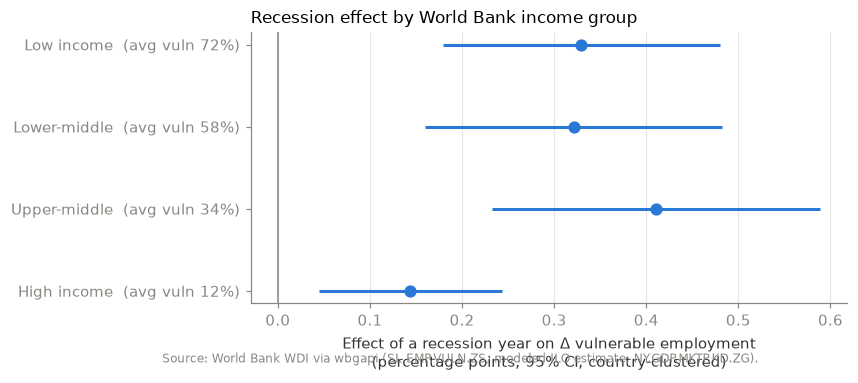

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.2))
y = np.arange(len(het))[::-1]
ax.errorbar(het["beta"], y, xerr=1.96 * het["se"], fmt="o", color=BLUE, ecolor=BLUE,
            elinewidth=2, capsize=0, markersize=7)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, [f"{g}  (avg vuln {v:.0f}%)" for g, v in zip(het.index, het["mean_vuln"])])
ax.set_xlabel("Effect of a recession year on Δ vulnerable employment\n(percentage points, 95% CI, country-clustered)")
ax.set_title("Recession effect by World Bank income group", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
finish(fig, "4_effect_by_income_group")

## 10. Conclusions and caveats

In [15]:
b = models["(3) + lagged recession"]
print("Key numbers")
print(f"  Raw difference in mean Δvuln (recession − normal):   {rec.mean() - norec.mean():+.3f} pp (p = {p:.3f})")
print(f"  FE effect, recession year:                           {b.params['recession']:+.3f} pp (p = {b.pvalues['recession']:.3f})")
print(f"  FE effect, year after recession:                     {b.params['recession_lag']:+.3f} pp (p = {b.pvalues['recession_lag']:.3f})")
g4 = models["(4) Continuous GDP growth"]
print(f"  FE effect of +1 pt GDP growth:                       {g4.params['gdp_growth']:+.4f} pp (p = {g4.pvalues['gdp_growth']:.3f})")
print(f"  Event study, t+4 vs t−1 relative to placebo:         {es['difference'].iloc[-1]:+.3f} pp")

Key numbers
  Raw difference in mean Δvuln (recession − normal):   +0.418 pp (p = 0.000)
  FE effect, recession year:                           +0.279 pp (p = 0.000)
  FE effect, year after recession:                     +0.200 pp (p = 0.000)
  FE effect of +1 pt GDP growth:                       -0.0209 pp (p = 0.000)
  Event study, t+4 vs t−1 relative to placebo:         +1.095 pp


### What the data say

**The hypothesis is supported.** Every approach finds that vulnerable employment rises during recessions:

* **Raw comparison.** In normal years vulnerable employment falls by about 0.23 pp a year on average; in recession years it *rises* by about 0.18 pp. The gap is ≈ 0.42 pp.
* **Fixed effects.** Comparing each country with itself and netting out global year shocks, a recession year adds ≈ 0.28 pp to the annual change, and the following year adds another ≈ 0.20 pp. In the continuous specification, each 1-point fall in real GDP growth raises vulnerable employment by ≈ 0.02 pp. All are significant at the 1% level with country-clustered SEs.
* **Persistence.** The event study suggests the effect doesn't reverse. Four years after onset, recession countries sit ≈ 1.1 pp above where the non-recession comparison group would predict. Recessions appear to interrupt the long-run move toward formal wage employment rather than causing a temporary blip.
* **Heterogeneity.** The effect is significant in every income group. It is largest in low and middle-income countries (≈ 0.3–0.4 pp) and about half that size in high-income countries (≈ 0.14 pp). This fits the mechanism: where informality is common and unemployment insurance is thin, workers who lose formal jobs move into own-account work instead of into unemployment.

### Caveats — read before citing these results

1. **ILO modeled estimates.** `SL.EMP.VULN.ZS` is not a raw survey measure. For country-years without labour-force surveys, the ILO *imputes* it with models that use macro variables, including GDP growth. Some of the recession–vulnerability link could be built into the data by construction. A robustness check would be to restrict to country-years with actual survey observations (ILOSTAT flags these).
2. **Pre-trend in the event study.** Before onset the difference line is already rising (−0.23 at t = −3 to 0 at t = −1). Countries that fall into recession were already formalising more slowly than the placebo group, so the event-study estimate probably *overstates* the recession effect somewhat. The within-country fixed-effects regression is less exposed to this than the event study.
3. **Comparison group.** The placebo windows (no recession for eight straight years) come mostly from fast-growing economies, so the event study partly compares different kinds of countries. The FE regression is the cleaner estimate.
4. **Recession definition.** Negative annual real GDP growth misses slowdowns and short recessions within a year. Output collapses from war or disaster (e.g. growth of −64%) are included as "recessions".
5. **Correlation, not a clean causal effect.** Recessions aren't randomly assigned. Crises that cause them, such as commodity busts or conflict, could affect labour markets through other channels too.